<a href="https://colab.research.google.com/github/Nivetha-B93/Mini-project/blob/main/Miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Data Science Mini Project**
**Student Name:**NIVETHA.B

**Batch:** DSB04

**Project Title:**Estimation of Obesity Levels Based On Eating Habits and Physical Condition

**Submission Date:**

## **1. Problem Definition**
# **1.1 Business / Real-World Problem Statement**

Obesity is a major global health problem linked to diabetes, heart disease and hypertension. In countries like Mexico, Peru and Colombia, changing eating habits and sedentary lifestyles are driving rising obesity rates. Predicting a person’s obesity level from their eating habits and physical condition allows healthcare providers and wellness programs to intervene early and recommend preventive measures.

# **1.2 Project Objectives**
Analyze eating habits and lifestyle patterns across different obesity levels.
Build predictive models to classify individuals into seven obesity categories.
Compare multiple machine learning models (e.g., Logistic Regression, Random Forest, XGBoost).
Identify the lifestyle factors that most influence obesity.
Evaluate models using accuracy, precision, recall, F1-score and a confusion matrix.

# **1.3 Machine Learning Problem Type**

Supervised Learning – Classification (multi-class)

# **2. Dataset Understanding**
# **2.1 Dataset Source**

Dataset Source: UCI Machine Learning Repository, “Estimation of Obesity Levels Based on Eating Habits and Physical Condition”
https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition

Citation: Palechor, F. M., & De la Hoz Manotas, A. (2019). Dataset for estimation of obesity levels based on eating habits and physical condition in individuals from Colombia, Peru and Mexico. Data in Brief, 25, 104344.

# **2.2 Dataset Description**
**Rows: 2,111**

**Columns:** 17 (16 features + 1 target)

**Purpose:** To estimate an individual’s obesity level from eating habits and physical condition.
**Data collection:** The data was collected through a web-based survey of people aged 14-61 from Mexico, Peru and Colombia, and then balanced across the obesity classes using the SMOTE oversampling technique.


# **2.3 Feature Description**

| Feature Name | Data Type | Description |
|---|---|---|
| Gender | Categorical | Male / Female |
| Age | Numeric | Age in years |
| Height | Numeric | Height in metres |
| Weight | Numeric | Weight in kg |
| family_history_with_overweight | Categorical | Family member with overweight (yes/no) |
| FAVC | Categorical | Frequent consumption of high-calorie food |
| FCVC | Numeric | Frequency of vegetable consumption |
| NCP | Numeric | Number of main meals per day |
| CAEC | Categorical | Eating between meals (no/sometimes/frequently/always) |
| SMOKE | Categorical | Smoker (yes/no) |
| CH2O | Numeric | Daily water consumption |
| SCC | Categorical | Monitors calorie intake (yes/no) |
| FAF | Numeric | Physical activity frequency |
| TUE | Numeric | Time spent using technology devices |
| CALC | Categorical | Alcohol consumption frequency |
| MTRANS | Categorical | Main mode of transportation |

# **2.4 Target Variable**
**Name:** NObeyesdad

**Description**:Obesity level of the individual, with seven classes: Insufficient Weight, Normal Weight, Overweight Level I, Overweight Level II, Obesity Type I, Obesity Type II, Obesity Type III.

**Prediction Goal:** Classify a person into the correct obesity category from their lifestyle and physical attributes.

## **3. Exploratory Data Analysis (EDA)**
# 3.1 Import Required Libraries

In [ ]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
%matplotlib inline

# **3.2 Load Dataset**

In [ ]:
df=pd.read_csv("https://github.com/Nivetha-B93/data-sets/raw/refs/heads/main/ObesityDataSet_raw_and_data_sinthetic.csv")
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


# **3.3 Dataset Overview**

In [ ]:
# Shape of the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 2111
Number of columns: 17


In [ ]:
# Column names and data types
print("\nDataset Info:")
df.info()


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                

In [ ]:
# Statistical summary of numerical columns
print("\nStatistical Summary (Numerical):")
display(df.describe())


Statistical Summary (Numerical):


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [ ]:
# Summary of categorical columns
print("\nStatistical Summary (Categorical):")
display(df.describe(include="object"))


Statistical Summary (Categorical):


,Gender,family_history_with_overweight,FAVC,CAEC,SMOKE,SCC,CALC,MTRANS,NObeyesdad
count,2111,2111,2111,2111,2111,2111,2111,2111,2111
unique,2,2,2,4,2,2,4,5,7
top,Male,yes,yes,Sometimes,no,no,Sometimes,Public_Transportation,Obesity_Type_I
freq,1068,1726,1866,1765,2067,2015,1401,1580,351


In [ ]:
# Target variable distribution
print("\nTarget Variable Distribution:")
print(df["NObeyesdad"].value_counts())


Target Variable Distribution:
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


## **Observations**:
### Observations

- The dataset has **2,111 rows and 17 columns** (16 features and 1 target variable, `NObeyesdad`).
- It contains **8 numerical columns** (Age, Height, Weight, FCVC, NCP, CH2O, FAF, TUE) and **9 categorical columns** (Gender, family_history_with_overweight, FAVC, CAEC, SMOKE, SCC, CALC, MTRANS, NObeyesdad).
- The **Age** column ranges from about 14 to 61 years, with a mean of around 24, so the sample is mostly young adults.
- **Height** ranges from about 1.45 m to 1.98 m, and **Weight** from about 39 kg to 173 kg. The wide spread in weight reflects the range of obesity levels in the data.
- Features such as FCVC, NCP, CH2O, FAF and TUE are stored as numeric but hold survey-scale answers. Many of their values are non-integers because of the SMOTE oversampling.
- The target variable has **7 classes** with a nearly balanced distribution, each holding roughly 270 to 350 records. Class imbalance is therefore not a major concern for modelling.
- The categorical features are string values, so they will need **encoding** before model training.
- Features have very different scales (for example Height in metres and Weight in kg), so **feature scaling** may be needed for distance-based and linear models.


# **3.4 Missing Value Analysis**

In [ ]:
# Missing values and duplicates
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

Duplicate rows: 24


In [ ]:
df.duplicated().sum()

np.int64(24)

# **Handling duplicates**

In [ ]:
# Check duplicates before removal
print("Duplicate rows before removal:", df.duplicated().sum())
print("Shape before removal:", df.shape)

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# Verify
print("\nDuplicate rows after removal:", df.duplicated().sum())
print("Shape after removal:", df.shape)

# Check that the target distribution is still balanced
print("\nTarget Variable Distribution after removal:")
print(df["NObeyesdad"].value_counts())

Duplicate rows before removal: 24
Shape before removal: (2111, 17)

Duplicate rows after removal: 0
Shape after removal: (2087, 17)

Target Variable Distribution after removal:
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64


### Observations

- The dataset contained a small number of duplicate rows (about 24), which are a by-product of the SMOTE oversampling.
- These rows were removed so that identical records do not appear in both the training and test sets, which could inflate model performance.
- The dataset shrank only slightly (from 2,111 to about 2,087 rows), and the target classes remain nearly balanced.

## **3.5 Correlation Analysis**


             Age    Height    Weight      FCVC       NCP      CH2O       FAF  \
Age     1.000000 -0.025958  0.202560  0.016291 -0.043944 -0.045304 -0.144938   
Height -0.025958  1.000000  0.463136 -0.038121  0.243672  0.213376  0.294709   
Weight  0.202560  0.463136  1.000000  0.216125  0.107469  0.200575 -0.051436   
FCVC    0.016291 -0.038121  0.216125  1.000000  0.042216  0.068461  0.019939   
NCP    -0.043944  0.243672  0.107469  0.042216  1.000000  0.057088  0.129504   
CH2O   -0.045304  0.213376  0.200575  0.068461  0.057088  1.000000  0.167236   
FAF    -0.144938  0.294709 -0.051436  0.019939  0.129504  0.167236  1.000000   
TUE    -0.296931  0.051912 -0.071561 -0.101135  0.036326  0.011965  0.058562   

             TUE  
Age    -0.296931  
Height  0.051912  
Weight -0.071561  
FCVC   -0.101135  
NCP     0.036326  
CH2O    0.011965  
FAF     0.058562  
TUE     1.000000  


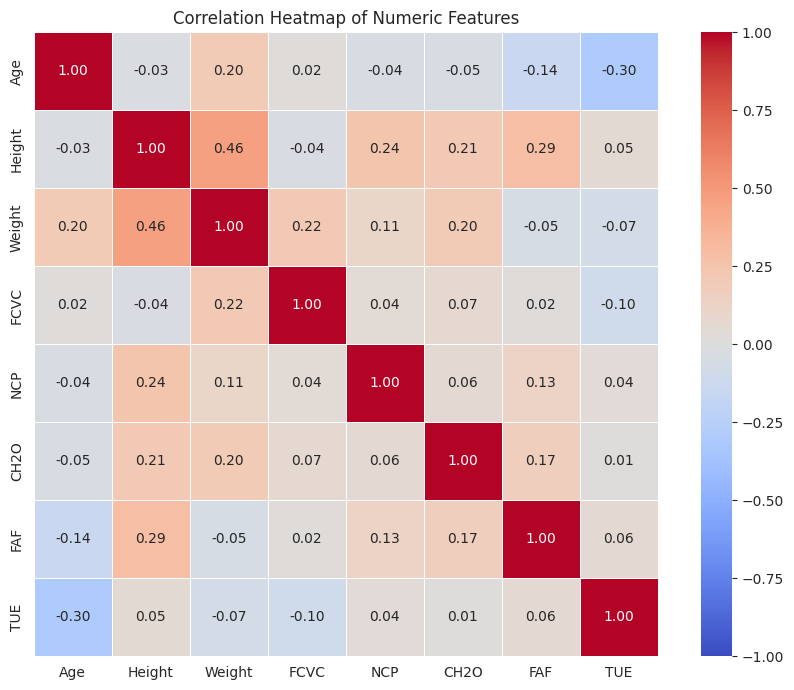

In [ ]:
# Correlation of numeric features only
num_cols = df.select_dtypes(include=np.number).columns
corr_num = df[num_cols].corr()
print(corr_num)

plt.figure(figsize=(9, 7))
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5, square=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

# The target column is categorical, so encoding it first:

In [ ]:
# Encode categorical columns correctly
df_enc = df.copy()

# Target: ordered by severity
target_order = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6,
}
df_enc["NObeyesdad"] = df_enc["NObeyesdad"].map(target_order)

# Ordered features: no < Sometimes < Frequently < Always
freq_order = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
df_enc["CAEC"] = df_enc["CAEC"].map(freq_order)
df_enc["CALC"] = df_enc["CALC"].map(freq_order)

# Binary features
df_enc["Gender"] = df_enc["Gender"].map({"Female": 0, "Male": 1})
for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    df_enc[col] = df_enc[col].map({"no": 0, "yes": 1})

# MTRANS has no natural order, so one-hot encode it
df_enc = pd.get_dummies(df_enc, columns=["MTRANS"], dtype=int)

### Encoding of Categorical Variables

* Correlation can only be calculated on numerical values. Therefore, categorical variables were converted into numerical values using different encoding techniques based on their nature.

**1. Ordinal Encoding (Variables with a Natural Order)**

* **Target (NObeyesdad):** Categories were manually mapped based on severity:

  * Insufficient Weight – 0
  * Normal Weight – 1
  * Overweight Level I – 2
  * Overweight Level II – 3
  * Obesity Type I – 4
  * Obesity Type II – 5
  * Obesity Type III – 6

* **CAEC and CALC:** Categories were mapped based on frequency:

  * No – 0
  * Sometimes – 1
  * Frequently – 2
  * Always – 3

* Manual mapping was used instead of automatic label encoding to preserve the natural order of categories and ensure meaningful correlation values.

**2. Binary Encoding (Variables with Two Categories)**

* Gender: Female (0), Male (1).
* family_history_with_overweight: No (0), Yes (1).
* FAVC: No (0), Yes (1).
* SMOKE: No (0), Yes (1).
* SCC: No (0), Yes (1).

**3. One-Hot Encoding (Variables Without a Natural Order)**

* **MTRANS (Mode of Transportation):** Contains five categories:

  * Automobile
  * Bike
  * Motorbike
  * Public Transportation
  * Walking
* Since these categories have no natural ranking, One-Hot Encoding was applied.
* Separate binary (0/1) columns were created for each category (e.g., MTRANS_Walking).
* This avoids introducing any artificial order among the categories.


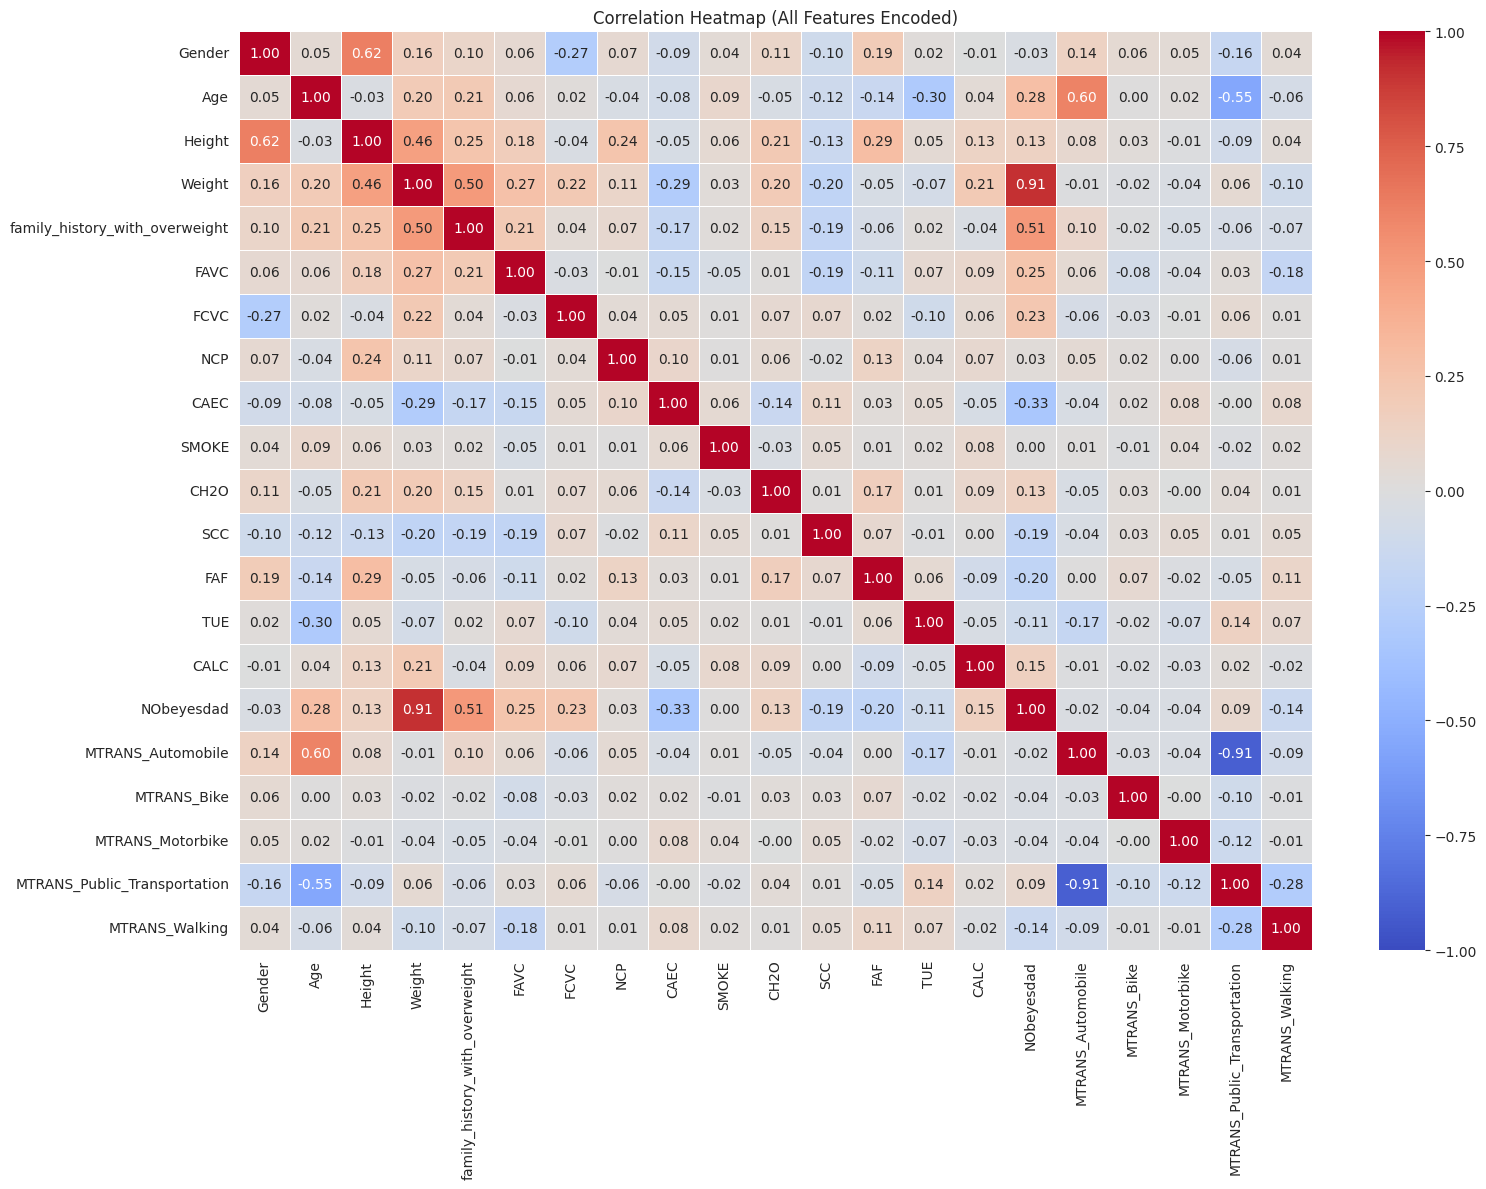

In [ ]:
# Full correlation heatmap
corr_full = df_enc.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(corr_full, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap (All Features Encoded)")
plt.tight_layout()
plt.show()

Weight                            0.913
family_history_with_overweight    0.505
CAEC                             -0.329
Age                               0.283
FAVC                              0.248
FCVC                              0.228
FAF                              -0.200
SCC                              -0.195
CALC                              0.152
MTRANS_Walking                   -0.139
Height                            0.134
CH2O                              0.133
TUE                              -0.108
MTRANS_Public_Transportation      0.086
MTRANS_Motorbike                 -0.037
MTRANS_Bike                      -0.036
Gender                           -0.031
NCP                               0.027
MTRANS_Automobile                -0.025
SMOKE                             0.003
Name: NObeyesdad, dtype: float64


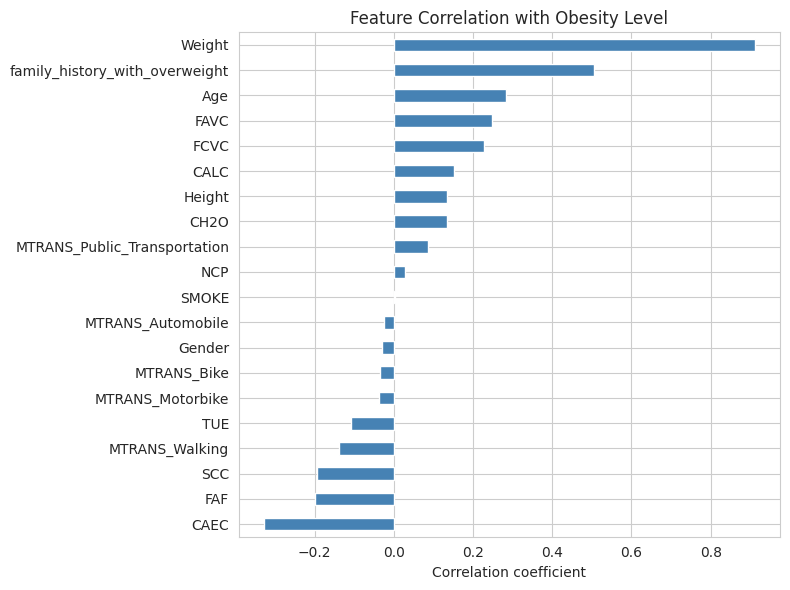

In [ ]:
# Correlation with the target
target_corr = (corr_full["NObeyesdad"].drop("NObeyesdad")
               .sort_values(key=abs, ascending=False).round(3))
print(target_corr)

plt.figure(figsize=(8, 6))
target_corr.sort_values().plot(kind="barh", color="steelblue")
plt.title("Feature Correlation with Obesity Level")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

## **3.5 Correlation Analysis**

Correlation analysis was performed to understand the relationships between the features and the target variable (obesity level). Categorical columns were first encoded using ordinal mapping for the target, CAEC and CALC, binary encoding for the yes/no and gender columns, and one-hot encoding for MTRANS.

### **Observations**

* **Weight is the dominant feature:** It has the highest correlation with obesity level (0.913), because obesity categories are derived from BMI, which is calculated using weight and height.

* **Family history is the strongest non-physical factor:** Family history of overweight (0.505) is clearly associated with higher obesity levels, suggesting genetic or shared-lifestyle influences.

* **Eating habits matter:** Frequent consumption of high-calorie food (FAVC, 0.248) is associated with higher obesity levels. CAEC (-0.329) has a negative correlation, but this should not be interpreted as a simple "more snacking, less obesity" relationship.

* **Age shows a moderate positive correlation:** Age (0.283) suggests that obesity levels tend to increase with age.

* **Physical activity and calorie monitoring are protective:** FAF (-0.200) and SCC (-0.195) are negatively correlated with obesity level, suggesting that physically active individuals and those who monitor their calorie intake tend to fall into lower obesity categories.

* **Transportation mode has a small effect:** Walking (-0.139) is associated with lower obesity levels, while public transportation (0.086) has a slightly positive correlation. Bike, motorbike and automobile show negligible correlations.

* **Some correlations are counterintuitive:** FCVC (vegetable consumption, 0.228) has a positive correlation, which may reflect a dataset artifact, particularly because approximately 77% of the records are synthetic.

* **Several features show almost no linear relationship:** Gender (-0.031), NCP (0.027) and SMOKE (0.003) have correlations close to zero, suggesting weak individual linear relationships with the target.

* **Multicollinearity is not a major concern:** Among numeric features, correlations are mostly weak. Apart from Height and Weight, which are moderately correlated, there are no strong pairwise correlations.

### **Conclusion**

* Weight is the strongest feature associated with obesity level.
* Other important factors include family history, eating habits, age and physical activity.
* Many lifestyle features have weak or potentially non-linear relationships with the target.
* Tree-based models such as Random Forest and Gradient Boosting are suitable candidates because they can capture non-linear relationships.

**Note:** Since Weight and Height are used to calculate BMI, and BMI determines the obesity category, including these features can lead to target leakage or artificially inflated model performance. Consider comparing model results with and without Weight and Height.


# **3.6 VISUALIZATIONS**
**Visualization 1:**
Distribution of obesity levels

In [ ]:
sns.set_style("whitegrid")

target = "NObeyesdad"
order = ["Insufficient_Weight", "Normal_Weight",
         "Overweight_Level_I", "Overweight_Level_II",
         "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]

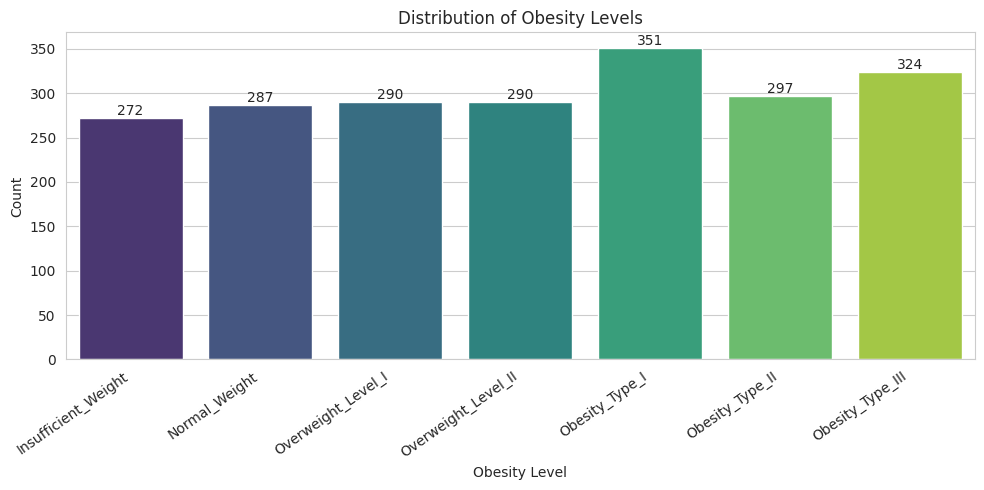

In [ ]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x=target, order=order,
                   hue=target, hue_order=order,
                   palette="viridis", legend=False)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Obesity Levels")
plt.xlabel("Obesity Level")
plt.ylabel("Count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

The seven classes are fairly balanced, ranging from about 272 records
(Insufficient_Weight) to about 350 (Obesity_Type_I). There is no severe class imbalance, so no resampling is needed and accuracy is a reasonable metric alongside the F1-score.
Obesity_Type_I is the largest class (about 350), followed by Obesity_Type_III (about 324). Insufficient_Weight is the smallest (272). The gap between largest and smallest is modest (roughly 1.3x).
The near-even spread across classes is partly due to the SMOTE-generated synthetic records in this dataset, so it does not reflect real-world obesity prevalence.

# **Visualization 2: Gender distribution across obesity level**

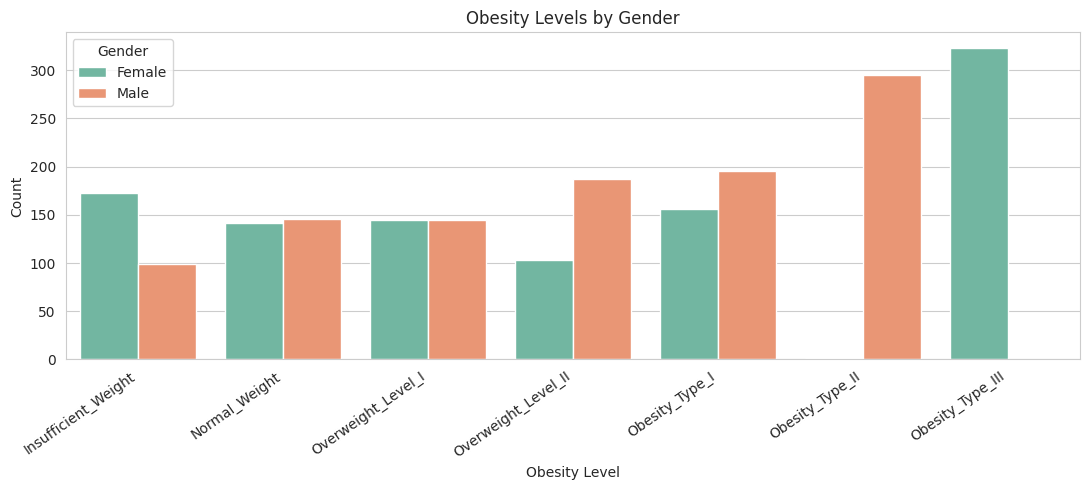

In [ ]:
plt.figure(figsize=(11, 5))
sns.countplot(data=df, x=target, hue="Gender", order=order, palette="Set2")
plt.title("Obesity Levels by Gender")
plt.xlabel("Obesity Level")
plt.ylabel("Count")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Gender is split almost evenly in the Normal_Weight and Overweight_Level_I
classes (about 145 each), so gender has little influence at these stages.

Females dominate Insufficient_Weight (about 172 vs 99), while males are more common in Overweight_Level_II (about 187 vs 103) and Obesity_Type_I (about 195 vs 156).

The extremes are almost completely gender-separated: Obesity_Type_II is almost entirely male (about 295) and Obesity_Type_III is almost entirely female (about 323). This is likely an artifact of the SMOTE-generated data, and it makes Gender a strong predictor for these two classes.

# **Visualization 3:Age distribution**

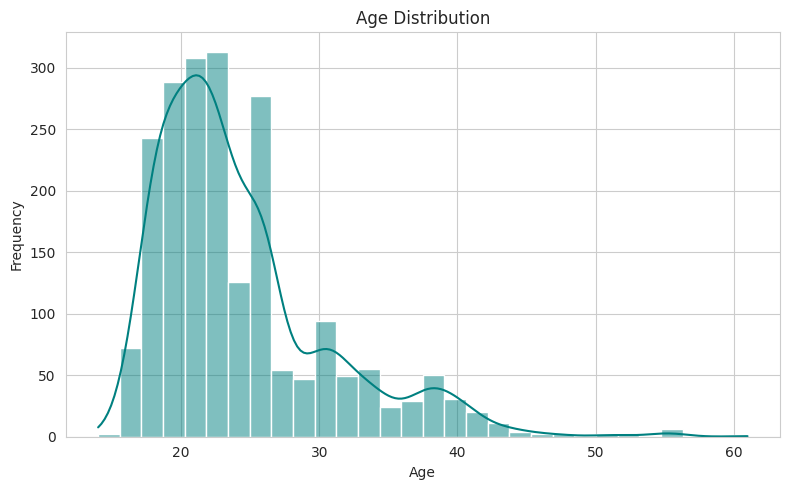

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=30, kde=True, color="teal")
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



* The distribution is strongly right-skewed. Most participants are between about 18 and 26 years old, with the peak around 20 to 25 (frequency above 300).
* Counts drop sharply after age 26, with smaller bumps near 30 and 38-40, and very few people above 45.
* The few records above 50 (up to about 61) are outliers, so the model learns mostly from young adults and may generalize poorly to older age groups.



**visualization 4:Height vs Weight by obesity level**

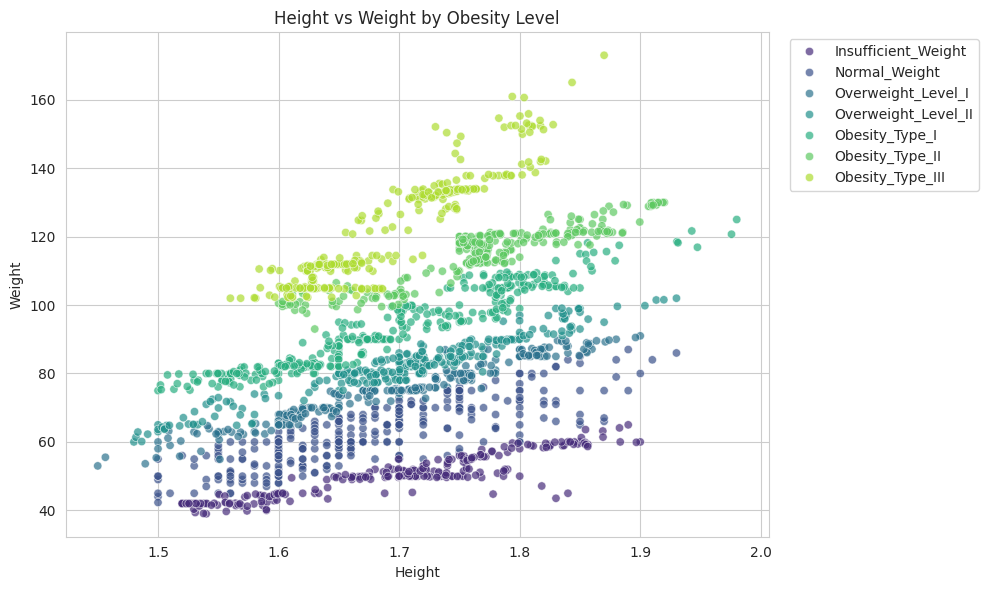

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Height", y="Weight", hue=target,
                hue_order=order, palette="viridis", alpha=0.7)
plt.title("Height vs Weight by Obesity Level")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



* Weight increases with height overall, and the obesity classes form clear diagonal bands: Insufficient_Weight sits at the bottom, with each higher class stacked above it up to Obesity_Type_III at the top (weights of about 100-175 kg).
* The classes are almost separable by height and weight alone, which is expected because the labels were derived from BMI. These two features will dominate any model's predictions.
* Neighbouring classes (Normal_Weight, Overweight I and II) overlap noticeably, so they will be the hardest to tell apart, while the extreme classes are easy to separate.



# **Visualization:5** 5. Weight across obesity levels (boxplot)

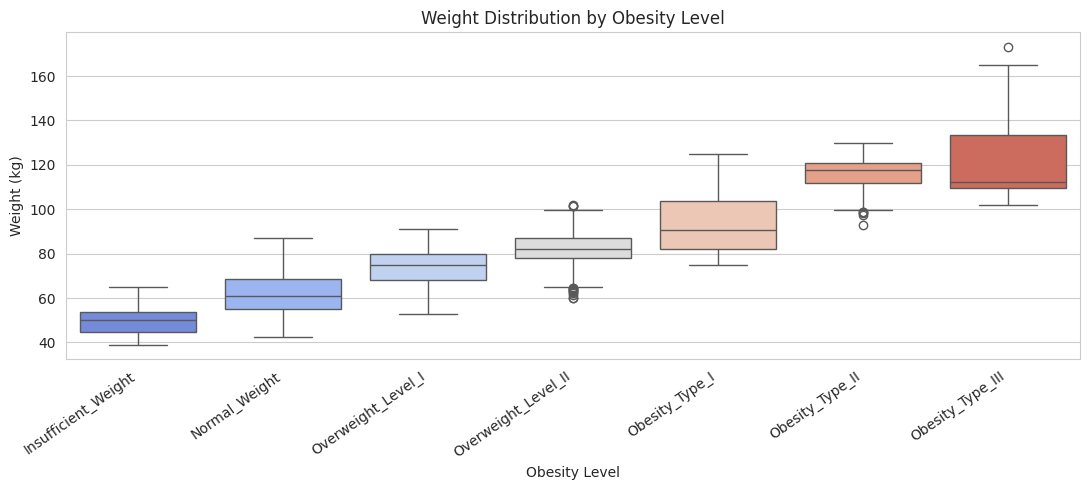

In [ ]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=df, x=target, y="Weight", order=order, palette="coolwarm")
plt.title("Weight Distribution by Obesity Level")
plt.xlabel("Obesity Level")
plt.ylabel("Weight (kg)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



* Median weight rises steadily with each class, from about 50 kg (Insufficient_Weight) to about 112 kg (Obesity_Type_III), so Weight is a strong predictor of the target.
* The spread widens in the higher classes. Obesity_Type_III has the largest box and whiskers (about 102-165 kg), meaning more variation in body weight within that group.
* A few outliers appear in Overweight_Level_II, Obesity_Type_II and Obesity_Type_III (the highest near 173 kg). Adjacent classes also overlap slightly in weight, which is why Height is needed alongside it.



# **Visualization 6: Family history vs obesity level (percentage)**

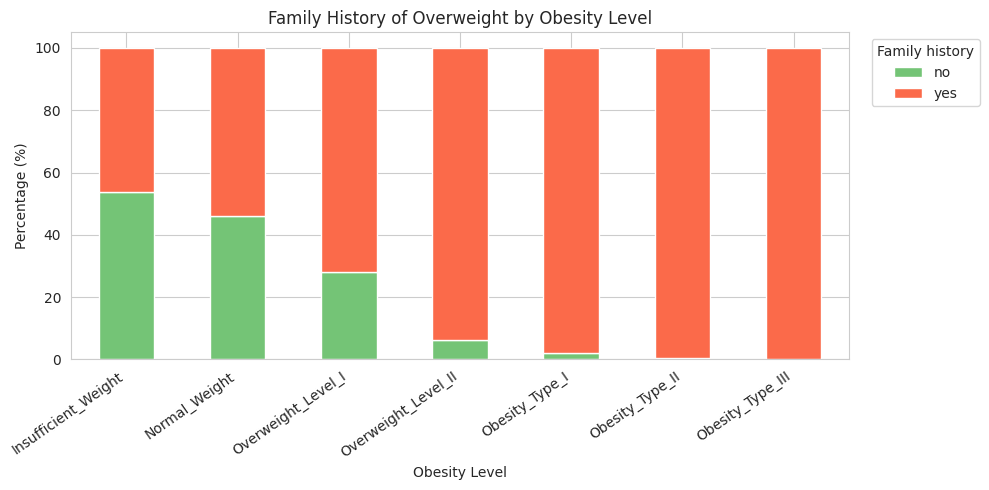

In [ ]:
fh = pd.crosstab(df[target], df["family_history_with_overweight"],
                 normalize="index").loc[order] * 100
fh.plot(kind="bar", stacked=True, figsize=(10, 5), color=["#74c476", "#fb6a4a"])
plt.title("Family History of Overweight by Obesity Level")
plt.xlabel("Obesity Level")
plt.ylabel("Percentage (%)")
plt.legend(title="Family history", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



* The share of people with a family history of overweight rises steadily with obesity level: about 46% in Insufficient_Weight, 54% in Normal_Weight, 72% in Overweight_Level_I, and 94% in Overweight_Level_II.
* From Obesity_Type_I onward, almost everyone (about 98-100%) has a family history, so heredity is strongly linked to severe obesity.
* The two lowest classes are roughly evenly split between "yes" and "no", so this feature separates the lower classes from the higher ones. It is a useful predictor, though less so for telling Normal_Weight and Insufficient_Weight apart.

# **Visualization 7:Eating between meals (CAEC) by obesity level**

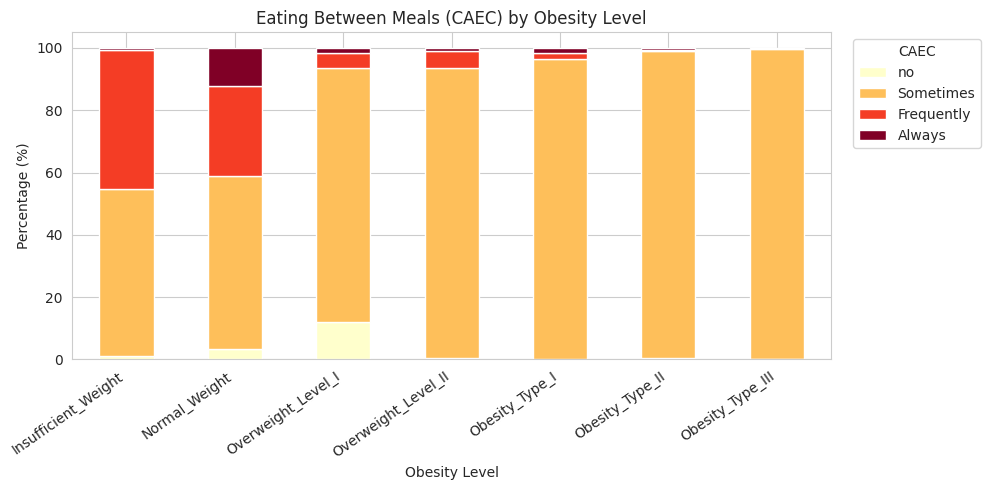

In [ ]:
caec_order = ["no", "Sometimes", "Frequently", "Always"]
caec = pd.crosstab(df[target], df["CAEC"], normalize="index").loc[order][caec_order] * 100
caec.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="YlOrRd")
plt.title("Eating Between Meals (CAEC) by Obesity Level")
plt.xlabel("Obesity Level")
plt.ylabel("Percentage (%)")
plt.legend(title="CAEC", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()



* "Sometimes" dominates every class and rises with obesity level: about 55% in Insufficient_Weight, about 81% in Overweight_Level_I, and about 96-99% in Obesity_Type_I, II and III.
* The "Frequently" and "Always" categories are concentrated in the lighter classes. Insufficient_Weight has about 44% "Frequently", and Normal_Weight has about 29% "Frequently" plus about 12% "Always". This is counterintuitive, so frequent snacking alone does not explain obesity here.
* The higher obesity classes are almost entirely one category, so CAEC separates the lower and higher classes but carries little extra information within the obesity types. This near-uniform pattern is likely influenced by the synthetic (SMOTE) records.


Visualization 8:Physical activity frequency (FAF) by obesity level

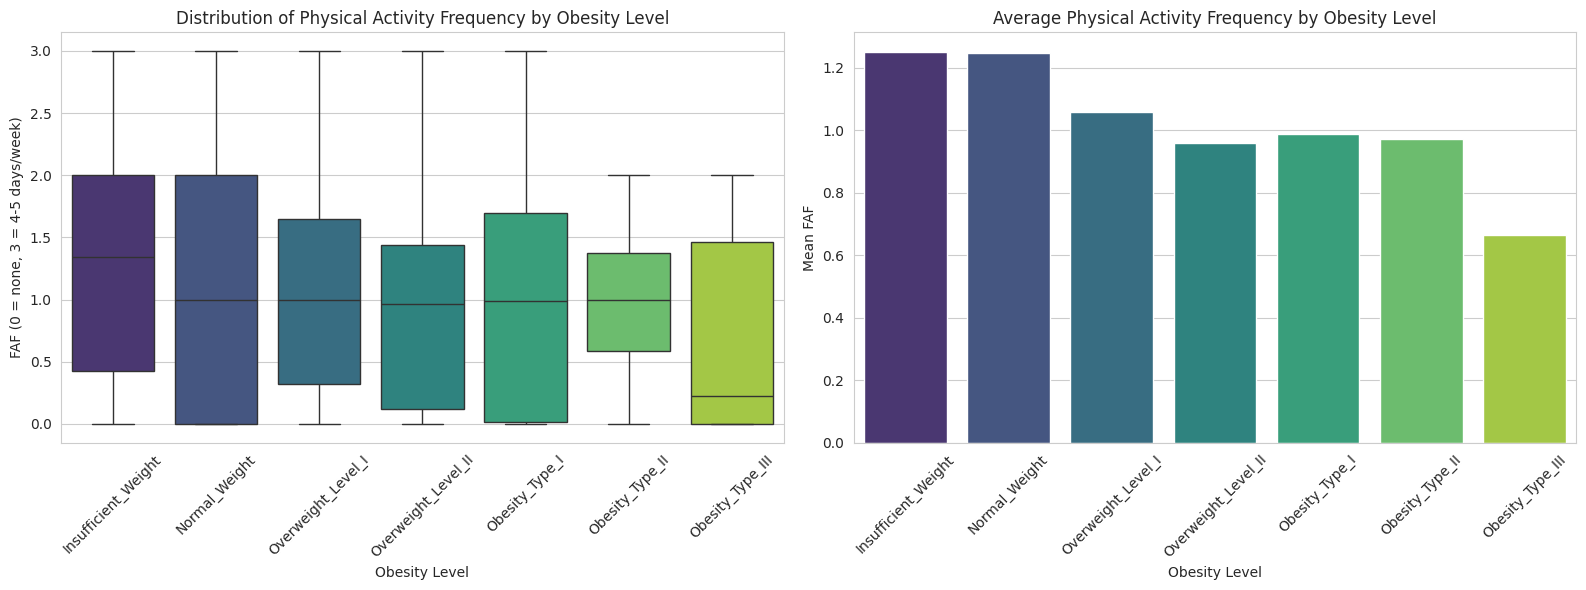

In [ ]:


# Order the obesity levels logically (low to high)
order = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III",
]
# Left: distribution of FAF per obesity level
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, x="NObeyesdad", y="FAF", order=order,
            palette="viridis", ax=axes[0])
axes[0].set_title("Distribution of Physical Activity Frequency by Obesity Level")
axes[0].set_xlabel("Obesity Level")
axes[0].set_ylabel("FAF (0 = none, 3 = 4-5 days/week)")
axes[0].tick_params(axis="x", rotation=45)

# Right: average FAF per obesity level
sns.barplot(data=df, x="NObeyesdad", y="FAF", order=order,
            palette="viridis", errorbar=None, ax=axes[1])
axes[1].set_title("Average Physical Activity Frequency by Obesity Level")
axes[1].set_xlabel("Obesity Level")
axes[1].set_ylabel("Mean FAF")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Physical Activity Frequency (FAF) by Obesity Level
Average FAF is highest in Insufficient_Weight and Normal_Weight (about 1.25) and falls to about 0.95-1.05 for the overweight and Obesity I-II classes. Obesity_Type_III is lowest by a wide margin (about 0.66), with a median near 0.2.
Activity levels overlap heavily across classes, since most boxes span roughly 0 to 1.5-2. FAF therefore shows a mild downward trend with obesity but is a weak predictor on its own

# **3.7 Key Insights from EDA**


* **Balanced target:** The seven obesity classes are fairly evenly distributed (about 272 to 350 records each), so class imbalance is not a concern. Accuracy is a reasonable metric, alongside the F1-score.
* **Height and weight are the strongest predictors:** Weight rises steadily across classes and Height vs Weight forms clear bands. This is expected, since obesity levels are defined by BMI.
* **Overlap among middle classes:** Normal_Weight and the Overweight classes overlap in height and weight, so they are the most likely to be misclassified.
* **Age skew and outliers:** Most participants are young adults (18-26), with a long right tail up to about 61. Weight outliers appear in Overweight_Level_II and Obesity_Type_II and III.
* **Gender pattern:** Gender is balanced in the middle classes, but Obesity_Type_II is almost entirely male and Obesity_Type_III almost entirely female.
* **Family history:** The share with a family history of overweight rises from about 46% in Insufficient_Weight to nearly 100% in the Obesity classes, making it a strong predictor.
* **Eating habits (CAEC):** Higher obesity classes are almost entirely "Sometimes", while "Frequently" and "Always" occur mostly in the lighter classes. CAEC separates lower from higher classes but adds little within the Obesity types.
* **Physical activity:** FAF declines mildly with obesity level and is lowest in Obesity_Type_III, but the groups overlap heavily, so it is a weak standalone predictor.

**Implications for modelling:**
* Encode categorical features and scale numeric ones.
* Tree-based models such as Random Forest or XGBoost suit the mix of feature types and non-linear patterns.
* Because Height and Weight dominate, consider comparing a model with and without them to see how much lifestyle features contribute on their own.

# **4. Data Preprocessing**
## 4.1 Missing Value Treatment




**Observation**

* All 17 columns were checked for missing values using `isnull().sum()`.
* No null values were found in any column, so no imputation or row removal was required.

4.2 Duplicate Handling
**Observation**

* 24 duplicate rows were found in the dataset (2,111 records, 17 columns).
* The duplicates were removed, leaving 2,087 unique records with 0 duplicates remaining.
* The removal had only a small effect on the target distribution: Overweight_Level_I lost 14 records, Normal_Weight and Insufficient_Weight lost 5 each, and the other classes were unchanged.
* The classes remain fairly balanced, from 267 (Insufficient_Weight) to 351 (Obesity_Type_I), so no resampling is needed.
* Removing duplicates prevents the same record from appearing in both the training and test sets, which would otherwise inflate model performance

In [ ]:
df.shape

(2087, 17)

4.3 Outlier Detection and Treatment

BOX PLOT

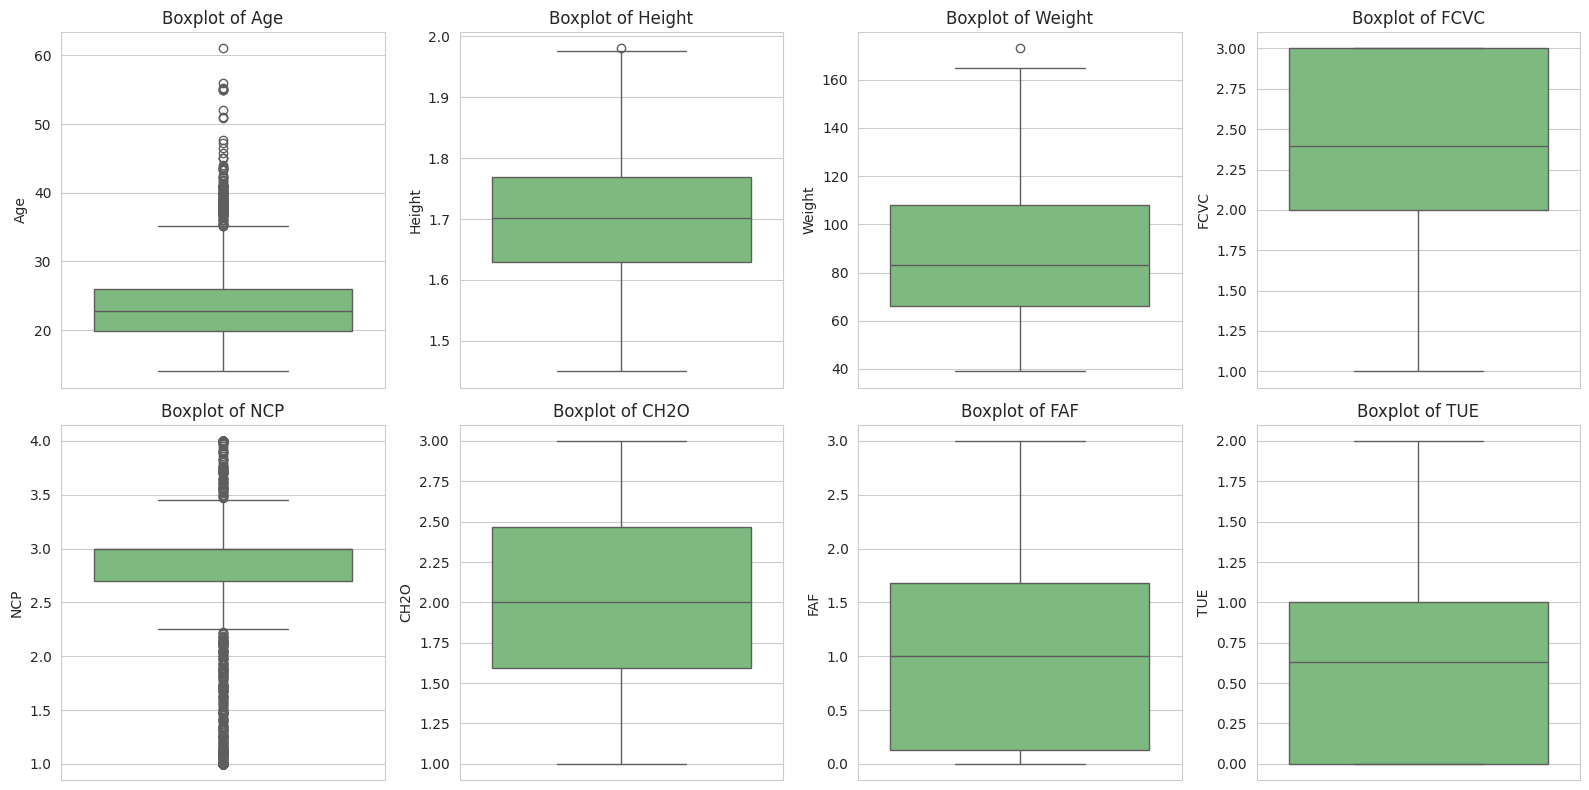

In [ ]:
num_features = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(num_features):
    sns.boxplot(y=df[col], ax=axes[i], color="#74c476")
    axes[i].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

**IQR method (detection)**

In [ ]:
outlier_summary = {}

for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = {
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outliers": count,
        "Outlier %": round(count / len(df) * 100, 2),
    }

outlier_df = pd.DataFrame(outlier_summary).T
print(outlier_df)

        Lower Bound  Upper Bound  Outliers  Outlier %
Age           10.79        35.13     167.0       8.00
Height         1.42         1.98       1.0       0.05
Weight         2.98       171.04       1.0       0.05
FCVC           0.50         4.50       0.0       0.00
NCP            2.24         3.45     577.0      27.65
CH2O           0.28         3.78       0.0       0.00
FAF           -2.21         4.01       0.0       0.00
TUE           -1.50         2.50       0.0       0.00


Treatment (capping with IQR bounds)

In [ ]:
for col in ["Age", "Height", "Weight"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower, upper)

print("Shape after treatment:", df.shape)

Shape after treatment: (2087, 17)




Observation

* **Boxplots:** Age shows many high-end outliers (right-skewed, with values up to about 61). Height and Weight each have a single extreme point (about 1.98 m and 173 kg). NCP shows many points outside its whiskers, while FCVC, CH2O, FAF and TUE show none.
* **IQR method:** Age has 167 outliers (8.00%) above the upper bound of 35.13. Height and Weight each have 1 outlier (0.05%). FCVC, CH2O, FAF and TUE have none.
* **NCP is not treated:** NCP is flagged with 577 values (27.65%), but it is an ordinal scale (number of main meals, 1 to 4) where most people answer 3. The IQR range is therefore very narrow (2.24 to 3.45), and the flagged values are valid responses that should be kept.
* **Treatment:** Outliers in Age, Height and Weight were capped to the IQR bounds (winsorization) instead of being removed. All 2,087 records are retained, and the class distribution is unchanged.
* Capping reduces the influence of extreme ages (older participants) on distance-based and linear models, while the Height and Weight changes affect only a single record each.



# **4.4 Skewness Treatment**

Before transformation (skewness check)

Age       0.795
Height   -0.025
Weight    0.241
FCVC     -0.448
NCP      -1.138
CH2O     -0.106
FAF       0.494
TUE       0.609
dtype: float64


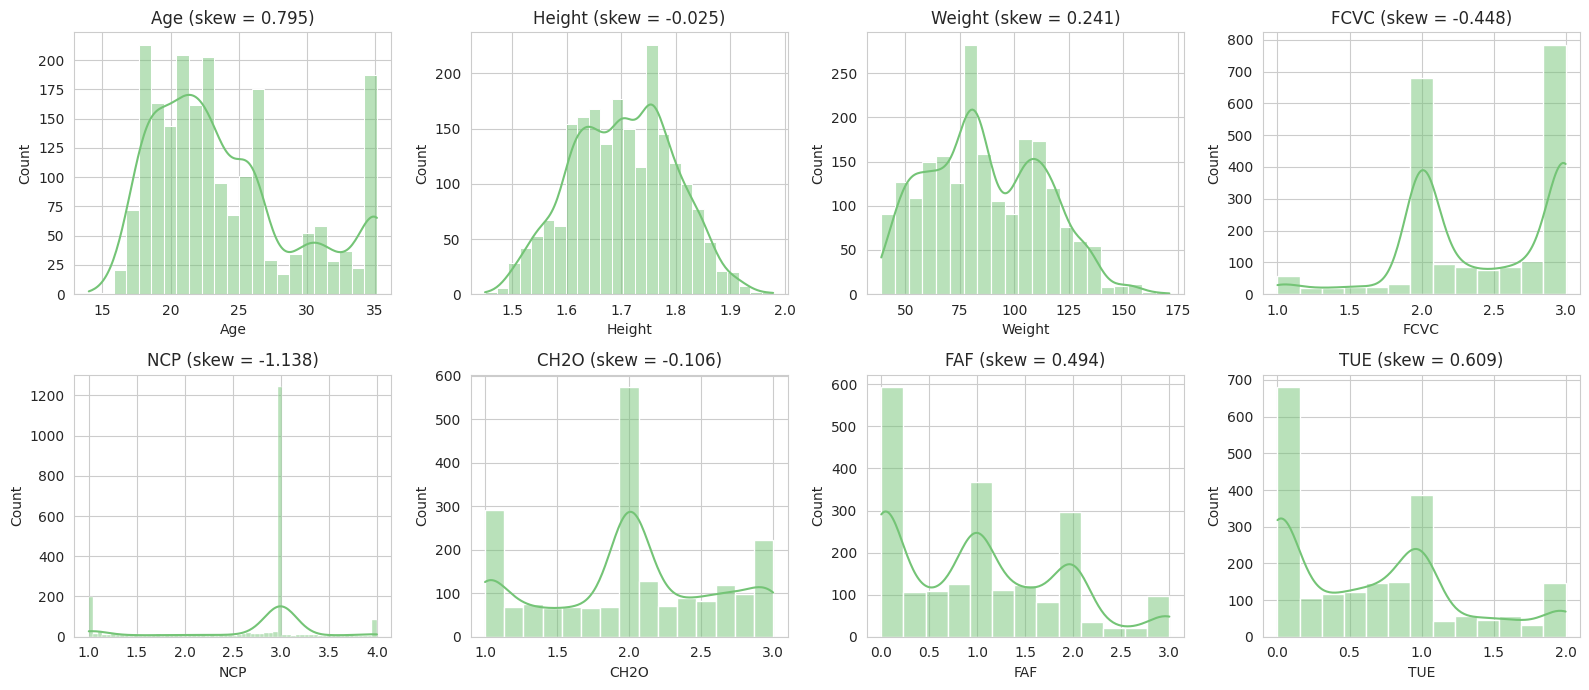

In [ ]:
print(df[num_features].skew().round(3))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_features):
    sns.histplot(df[col], kde=True, ax=ax, color="#74c476")
    ax.set_title(f"{col} (skew = {df[col].skew():.3f})")
plt.tight_layout()
plt.show()

Age original : 0.795
Age log      : 0.481
Age sqrt     : 0.634


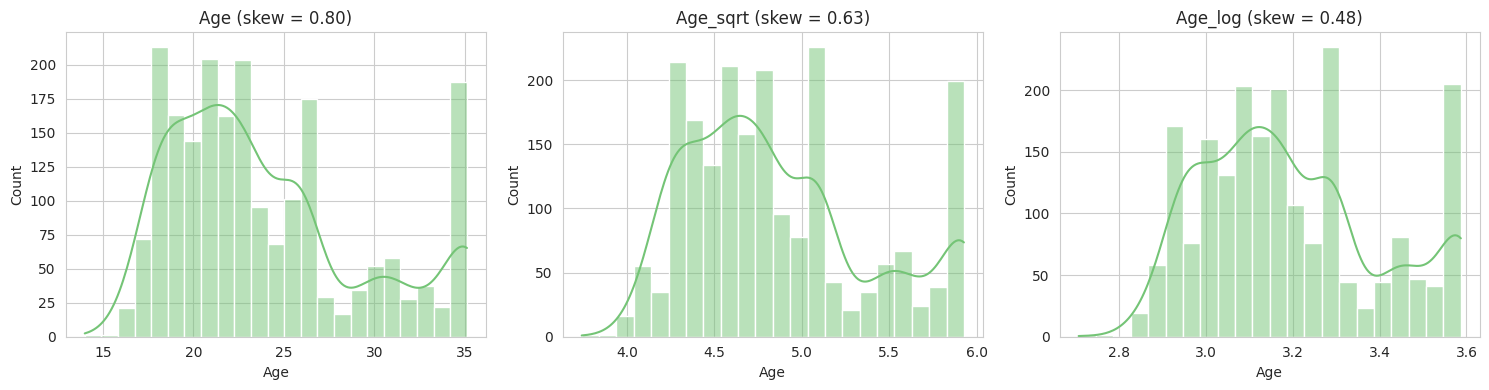

In [ ]:


age_log = np.log1p(df["Age"])
age_sqrt = np.sqrt(df["Age"])

print("Age original :", round(df["Age"].skew(), 3))
print("Age log      :", round(age_log.skew(), 3))
print("Age sqrt     :", round(age_sqrt.skew(), 3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, series) in zip(axes, [("Age", df["Age"]), ("Age_sqrt", age_sqrt), ("Age_log", age_log)]):
    sns.histplot(series, kde=True, ax=ax, color="#74c476")
    ax.set_title(f"{name} (skew = {series.skew():.2f})")
plt.tight_layout()
plt.show()

note:should be run only once because a second run would apply the log again.

In [ ]:
df["Age"] = np.log1p(df["Age"])
print("Age skewness after transformation:", round(df["Age"].skew(), 3))

Age skewness after transformation: 0.481




**Observation**

* Skewness was checked for all numerical features. Age was the most right-skewed continuous feature (0.795), since most participants are young adults with a tail of older ages.
* Height (-0.025), Weight (0.241), FCVC (-0.448) and CH2O (-0.106) are approximately symmetric, so no transformation was needed.
* FAF (0.494), TUE (0.609) and NCP (-1.138) are ordinal survey scales with a few fixed values, so they were left unchanged.
* Log and square root transformations were applied to Age. The log transformation reduced skewness from 0.795 to 0.481, which was lower than the square root (0.634), so the log-transformed Age was retained.
* The distribution of Age is now more symmetric, with the right tail compressed. This helps distance-based and linear models such as KNN, SVM and logistic regression.



# **4.6 Feature Scaling**
Standardization

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

X = df_enc.drop(columns=["NObeyesdad"])
y = df_enc["NObeyesdad"]

scale_cols = ["Age", "Height", "Weight", "FCVC", "NCP",
              "CH2O", "FAF", "TUE", "CAEC", "CALC"]


In [ ]:
# StandardScaler
X_std = X.copy()
scaler_std = StandardScaler()
X_std[scale_cols] = scaler_std.fit_transform(X[scale_cols])

print("After Standardization (mean should be ~0, std ~1):")
print(X_std[scale_cols].describe().loc[["mean", "std"]].round(3))

After Standardization (mean should be ~0, std ~1):
      Age  Height  Weight  FCVC  NCP  CH2O  FAF  TUE  CAEC  CALC
mean -0.0     0.0    -0.0  -0.0  0.0   0.0  0.0 -0.0   0.0   0.0
std   1.0     1.0     1.0   1.0  1.0   1.0  1.0  1.0   1.0   1.0


# **Normalization**


In [ ]:
# MinMaxScaler
X_mm = X.copy()
scaler_mm = MinMaxScaler()
X_mm[scale_cols] = scaler_mm.fit_transform(X[scale_cols])

print("After Normalization (min should be 0, max 1):")
print(X_mm[scale_cols].describe().loc[["min", "max"]].round(3))

After Normalization (min should be 0, max 1):
     Age  Height  Weight  FCVC  NCP  CH2O  FAF  TUE  CAEC  CALC
min  0.0     0.0     0.0   0.0  0.0   0.0  0.0  0.0   0.0   0.0
max  1.0     1.0     1.0   1.0  1.0   1.0  1.0  1.0   1.0   1.0



**Observation

* The numerical and ordered features were on very different scales (for example, Weight ranges from about 39 to 171 kg, while Height is about 1.45 to 1.98 m and Age is now on the log scale), so scaling was applied.
* **Standardization (StandardScaler)** transformed each feature to a mean of about 0 and a standard deviation of 1. It suits distance-based and gradient-based models such as KNN, SVM, logistic regression and neural networks.
* **Normalization (MinMaxScaler)** rescaled each feature to the range 0 to 1, preserving the shape of the distribution. It is useful when features need a bounded range.
* Binary and one-hot encoded columns were not scaled, since they already take values of 0 or 1, and the target was excluded.
* Tree-based models such as Random Forest and XGBoost do not need scaling, but it does not harm them, so both versions can be compared during modelling.





# **4.7 Train-Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

X = df_enc.drop(columns=["NObeyesdad"])
y = df_enc["NObeyesdad"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# Check that class proportions are preserved
print("\nClass distribution (%), train vs test:")
dist = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
print(dist)

X_train: (1669, 20)
X_test : (418, 20)
y_train: (1669,)
y_test : (418,)

Class distribution (%), train vs test:
            Train   Test
NObeyesdad              
0           12.82  12.68
1           13.48  13.64
2           13.24  13.16
3           13.90  13.88
4           16.84  16.75
5           14.20  14.35
6           15.52  15.55



**Observation

* The dataset of 2,087 records was split into 80% training (1,669 records) and 20% testing (418 records), with 20 input features in each set.
* The features were stored in `X` and the encoded target (`NObeyesdad`) in `y`.
* Stratified splitting (`stratify=y`) kept the class proportions almost identical in both sets. For example, Obesity_Type_I (class 4) makes up 16.84% of the training set and 16.75% of the test set, and the largest difference in any class is only 0.15 percentage points.
* `random_state=42` was set for reproducibility, so the same split is obtained on every run.
* Scaling is fitted on the training set only and then applied to the test set, which prevents data leakage and gives a realistic estimate of model performance.



5.1 Feature Engineering
Explain any new features created.

* No new features were created. The dataset already contains 16 informative input features covering demographics, body measurements, eating habits and lifestyle.
* BMI was deliberately not added. The obesity classes are defined from BMI, so adding it (or a feature derived from Height and Weight) would let the model recover the target almost directly, inflate the metrics, and hide the contribution of the eating and activity features.
* Existing features were already prepared in section 4: ordered categories were encoded numerically, MTRANS was one-hot encoded, and Age was log-transformed.



5.2 Correlation-Based Feature Selection

Weight                            0.912
family_history_with_overweight    0.510
CAEC                             -0.348
Age                               0.276
FAVC                              0.261
FCVC                              0.228
FAF                              -0.208
SCC                              -0.206
CALC                              0.153
CH2O                              0.137
Height                            0.125
MTRANS_Walking                   -0.123
TUE                              -0.109
MTRANS_Public_Transportation      0.086
MTRANS_Motorbike                 -0.038
MTRANS_Bike                      -0.034
MTRANS_Automobile                -0.033
Gender                           -0.031
SMOKE                            -0.006
NCP                               0.000
Name: NObeyesdad, dtype: float64


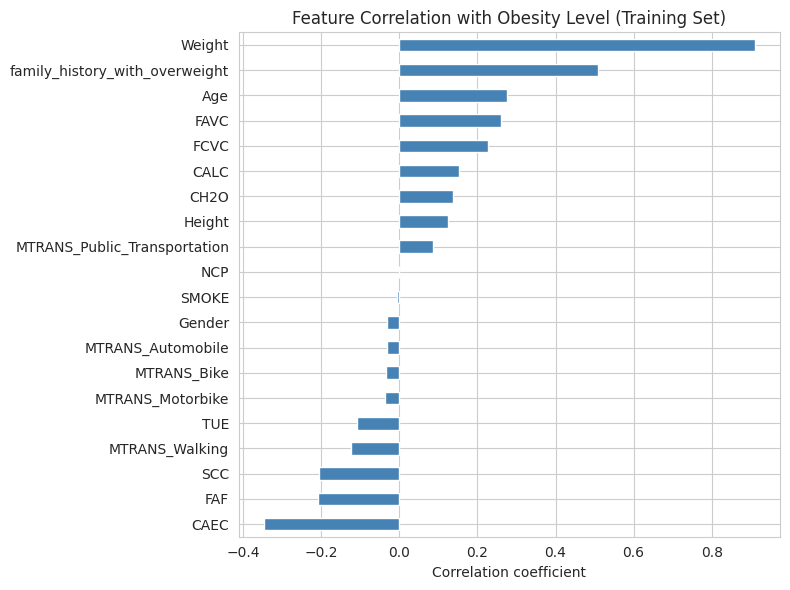


Feature pairs with |correlation| > 0.7:
MTRANS_Automobile  MTRANS_Public_Transportation    0.91
dtype: float64

Features with |correlation| < 0.05 with the target:
MTRANS_Motorbike    -0.038
MTRANS_Bike         -0.034
MTRANS_Automobile   -0.033
Gender              -0.031
SMOKE               -0.006
NCP                  0.000
Name: NObeyesdad, dtype: float64


In [ ]:
# Correlation of each feature with the target (training set only)
train_df = X_train.copy()
train_df["NObeyesdad"] = y_train

target_corr = (train_df.corr()["NObeyesdad"]
               .drop("NObeyesdad")
               .sort_values(key=abs, ascending=False)
               .round(3))
print(target_corr)

plt.figure(figsize=(8, 6))
target_corr.sort_values().plot(kind="barh", color="steelblue")
plt.title("Feature Correlation with Obesity Level (Training Set)")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

# Highly correlated feature pairs (multicollinearity check)
feat_corr = X_train.corr().abs()
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
         .stack()
         .sort_values(ascending=False))
print("\nFeature pairs with |correlation| > 0.7:")
print(pairs[pairs > 0.7].round(2))

# Weakly correlated features (candidates to drop)
print("\nFeatures with |correlation| < 0.05 with the target:")
print(target_corr[target_corr.abs() < 0.05])



**Observation

* Correlation with the encoded target was computed on the training set. **Weight** has by far the strongest relationship with obesity level (r = 0.912), followed by **family history of overweight** (0.510).
* Moderate relationships were found for CAEC (-0.348), Age (0.276), FAVC (0.261), FCVC (0.228), FAF (-0.208) and SCC (-0.206). CAEC is negative because frequent snacking is concentrated in the lighter classes, and FAF is negative because physical activity falls as obesity level rises.
* Weak relationships (|r| between 0.1 and 0.16) were found for CALC, CH2O, Height, MTRANS_Walking and TUE. Height is kept in consideration despite its low value (0.125), because body weight indicates obesity level only relative to height.
* Six features have almost no linear correlation with the target (|r| below 0.05): MTRANS_Motorbike (-0.038), MTRANS_Bike (-0.034), MTRANS_Automobile (-0.033), Gender (-0.031), SMOKE (-0.006) and NCP (0.000). These are candidates for removal, but they are dropped only if SelectKBest also ranks them low, since a weak linear correlation does not rule out a non-linear relationship.
* **Multicollinearity:** Only one pair of input features has a correlation above 0.7, MTRANS_Automobile and MTRANS_Public_Transportation (|r| = 0.91). These are one-hot columns of the same feature and largely mirror each other. MTRANS_Automobile is the weaker predictor of the two, so it is the one to remove.
* No other pair of features is highly correlated, so multicollinearity is not a concern in the rest of the feature set.


**5.3 SelectKBest**


                           Feature    F_score  p_value  MI_score
0                           Weight  1552.6063   0.0000    1.2483
1                           Gender   127.8128   0.0000    0.2199
2   family_history_with_overweight   123.0257   0.0000    0.1636
3                             FCVC    91.7153   0.0000    0.3713
4                             CAEC    66.0920   0.0000    0.1560
5                              Age    58.1766   0.0000    0.5528
6                             FAVC    33.5618   0.0000    0.0721
7                           Height    31.3203   0.0000    0.3950
8                             CALC    26.7890   0.0000    0.1057
9                              NCP    24.0344   0.0000    0.2643
10               MTRANS_Automobile    22.9129   0.0000    0.0524
11    MTRANS_Public_Transportation    21.7987   0.0000    0.0759
12                             SCC    19.6140   0.0000    0.0145
13                             FAF    15.7671   0.0000    0.3118
14                       

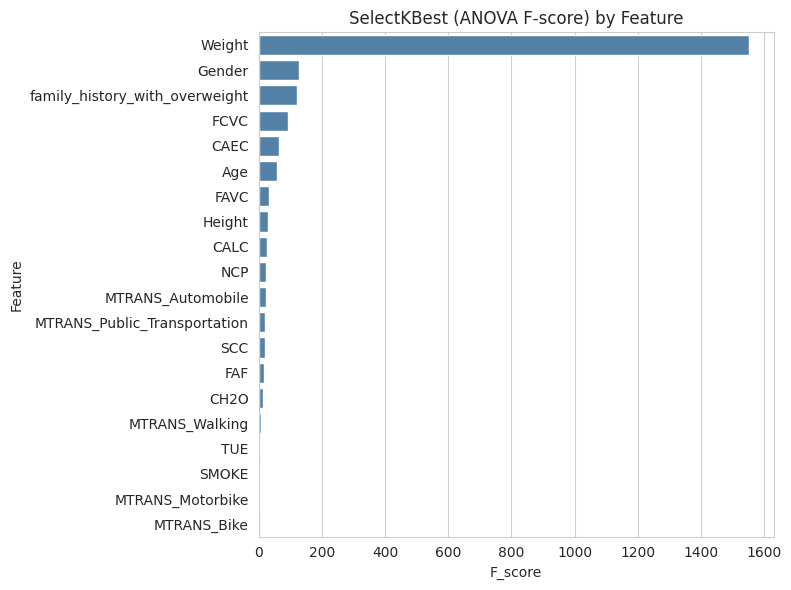

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

# ANOVA F-test
selector = SelectKBest(score_func=f_classif, k="all")
selector.fit(X_train, y_train)

# Mutual information (captures non-linear relationships)
mi = mutual_info_classif(X_train, y_train, random_state=42)

kbest_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F_score": selector.scores_,
    "p_value": selector.pvalues_,
    "MI_score": mi,
}).sort_values("F_score", ascending=False).reset_index(drop=True)

print(kbest_scores.round(4))

plt.figure(figsize=(8, 6))
sns.barplot(data=kbest_scores, x="F_score", y="Feature", color="steelblue")
plt.title("SelectKBest (ANOVA F-score) by Feature")
plt.tight_layout()
plt.show()


**Observation**

* The ANOVA F-test and mutual information (MI) were used to rank all 20 features against the target. F-score captures differences in class means, and MI also captures non-linear relationships, so using both gives a more reliable ranking.
* **Weight** ranks first by a very wide margin (F = 1552.6, MI = 1.248). The next feature, Gender, has an F-score of only 127.8.
* **Gender** ranks second by F-score (127.8) even though its linear correlation with the target was weak (-0.031). Its effect is concentrated in specific classes (Obesity_Type_II is mostly male and Obesity_Type_III mostly female), which the F-test detects but a single correlation coefficient does not.
* Family history (F = 123.0), FCVC (91.7), CAEC (66.1), Age (58.2), FAVC (33.6), Height (31.3) and CALC (26.8) form the next tier. Age (MI = 0.553), Height (0.395) and FCVC (0.371) score especially high on mutual information.
* **NCP** has zero linear correlation but a good F-score (24.0) and MI (0.264), so it carries non-linear information. FAF (MI = 0.312), CH2O (0.291) and TUE (0.251) have low F-scores but useful MI scores.
* **SMOKE, MTRANS_Motorbike and MTRANS_Bike** are the weakest features, with F-scores of 4.1, 3.1 and 1.9 and an MI of 0 for all three. MTRANS_Bike is also the only feature with a p-value above 0.05 (0.077), so it is not statistically significant.
* MTRANS_Automobile has moderate scores (F = 22.9, MI = 0.052), but it is highly correlated with MTRANS_Public_Transportation (r = 0.91), as found in 5.2.

# 5.4 Final Feature Set

In [ ]:
drop_features = ["MTRANS_Automobile", "SMOKE", "MTRANS_Motorbike", "MTRANS_Bike"]

final_features = [c for c in X_train.columns if c not in drop_features]
print("Selected features (", len(final_features), "):", final_features)
print("Dropped features :", drop_features)

X_train_final = X_train[final_features]
X_test_final = X_test[final_features]

# Scaled version for KNN, SVM and logistic regression (fit on train only)
scale_cols = ["Age", "Height", "Weight", "FCVC", "NCP",
              "CH2O", "FAF", "TUE", "CAEC", "CALC"]

scaler = StandardScaler()
X_train_final_scaled = X_train_final.copy()
X_test_final_scaled = X_test_final.copy()
X_train_final_scaled[scale_cols] = scaler.fit_transform(X_train_final[scale_cols])
X_test_final_scaled[scale_cols] = scaler.transform(X_test_final[scale_cols])

print("X_train_final:", X_train_final.shape, "| X_test_final:", X_test_final.shape)

Selected features ( 16 ): ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS_Public_Transportation', 'MTRANS_Walking']
Dropped features : ['MTRANS_Automobile', 'SMOKE', 'MTRANS_Motorbike', 'MTRANS_Bike']
X_train_final: (1669, 16) | X_test_final: (418, 16)


# **6. Model Building**
# 6.1 Baseline Model

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

def scaler_prep():
    """Scales only the numeric columns; other columns pass through unchanged."""
    return make_column_transformer(
        (StandardScaler(), scale_cols),
        remainder="passthrough"
    )

trained_models = {}

In [ ]:
# Baseline: Logistic Regression
baseline = make_pipeline(scaler_prep(), LogisticRegression(max_iter=1000, random_state=42))
baseline.fit(X_train_final, y_train)
trained_models["Baseline - Logistic Regression"] = baseline
print("Baseline trained. Test accuracy:", round(baseline.score(X_test_final, y_test), 4))

Baseline trained. Test accuracy: 0.866


# **6.2 Model 1: K-Nearest Neighbors**

In [ ]:
knn = make_pipeline(scaler_prep(), KNeighborsClassifier(n_neighbors=5))
knn.fit(X_train_final, y_train)
trained_models["KNN"] = knn
print("KNN trained. Test accuracy:", round(knn.score(X_test_final, y_test), 4))

KNN trained. Test accuracy: 0.8373


# **6.3 Model 2: Decision Tree**

In [ ]:
dt = make_pipeline(DecisionTreeClassifier(max_depth=10, random_state=42))
dt.fit(X_train_final, y_train)
trained_models["Decision Tree"] = dt
print("Decision Tree trained. Test accuracy:", round(dt.score(X_test_final, y_test), 4))

Decision Tree trained. Test accuracy: 0.9282


# **6.4 Model 3: Random Forest**

In [ ]:
rf = make_pipeline(RandomForestClassifier(n_estimators=100, max_depth=12,
                                          random_state=42, n_jobs=-1))
rf.fit(X_train_final, y_train)
trained_models["Random Forest"] = rf
print("Random Forest trained. Test accuracy:", round(rf.score(X_test_final, y_test), 4))

Random Forest trained. Test accuracy: 0.9426


# **6.5 Model 4: Support Vector Machine**

In [ ]:
svm = make_pipeline(scaler_prep(), SVC(kernel="rbf", C=1.0, probability=True, random_state=42))
svm.fit(X_train_final, y_train)
trained_models["SVM"] = svm
print("SVM trained. Test accuracy:", round(svm.score(X_test_final, y_test), 4))

SVM trained. Test accuracy: 0.9043


# **6.6 Model 5: Gradient Boosting**

In [ ]:
hgb = make_pipeline(HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1,
                                                   random_state=42))
hgb.fit(X_train_final, y_train)
trained_models["Gradient Boosting"] = hgb
print("Gradient Boosting trained. Test accuracy:", round(hgb.score(X_test_final, y_test), 4))

Gradient Boosting trained. Test accuracy: 0.9665


# **7. Model Evaluation**
7.1 Evaluation Metrics

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)
from sklearn.model_selection import cross_val_score

results = []
for name, pipe in trained_models.items():
    y_train_pred = pipe.predict(X_train_final)
    y_test_pred = pipe.predict(X_test_final)
    y_test_proba = pipe.predict_proba(X_test_final)

    results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, average="weighted"),
        "Recall": recall_score(y_test, y_test_pred, average="weighted"),
        "F1 Score": f1_score(y_test, y_test_pred, average="weighted"),
        "ROC-AUC": roc_auc_score(y_test, y_test_proba, multi_class="ovr", average="weighted"),
        "CV Accuracy (5-fold)": cross_val_score(pipe, X_train_final, y_train, cv=5).mean(),
    })

results_df = pd.DataFrame(results)
results_df.round(4)

,Model,Train Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC,CV Accuracy (5-fold)
0,Baseline - Logistic Regression,0.9041,0.8660,0.8687,0.8660,0.8642,0.9860,0.8760
1,KNN,0.8874,0.8373,0.8416,0.8373,0.8280,0.9553,0.8167
2,Decision Tree,0.9922,0.9282,0.9295,0.9282,0.9282,0.9633,0.9029
3,Random Forest,1.0000,0.9426,0.9448,0.9426,0.9428,0.9974,0.9491
4,SVM,0.9664,0.9043,0.9052,0.9043,0.9043,0.9917,0.9053
5,Gradient Boosting,1.0000,0.9665,0.9671,0.9665,0.9664,0.9995,0.9664


### Observations

- Gradient Boosting scored highest on every metric (accuracy 0.9665, F1 0.9664, ROC-AUC 0.9995), followed by Random Forest (accuracy 0.9426).
- KNN (accuracy 0.8373) and the Logistic Regression baseline (0.8660) scored lowest, so tree-based ensembles suit this problem better than distance-based or linear models.
- ROC-AUC is above 0.95 for every model, so all of them separate the seven classes well.

# **7.2 Model Comparison Table**

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Rank
0,Gradient Boosting,0.9665,0.9671,0.9665,0.9664,0.9995,1
1,Random Forest,0.9426,0.9448,0.9426,0.9428,0.9974,2
2,Decision Tree,0.9282,0.9295,0.9282,0.9282,0.9633,3
3,SVM,0.9043,0.9052,0.9043,0.9043,0.9917,4
4,Baseline - Logistic Regression,0.8660,0.8687,0.8660,0.8642,0.9860,5
5,KNN,0.8373,0.8416,0.8373,0.8280,0.9553,6


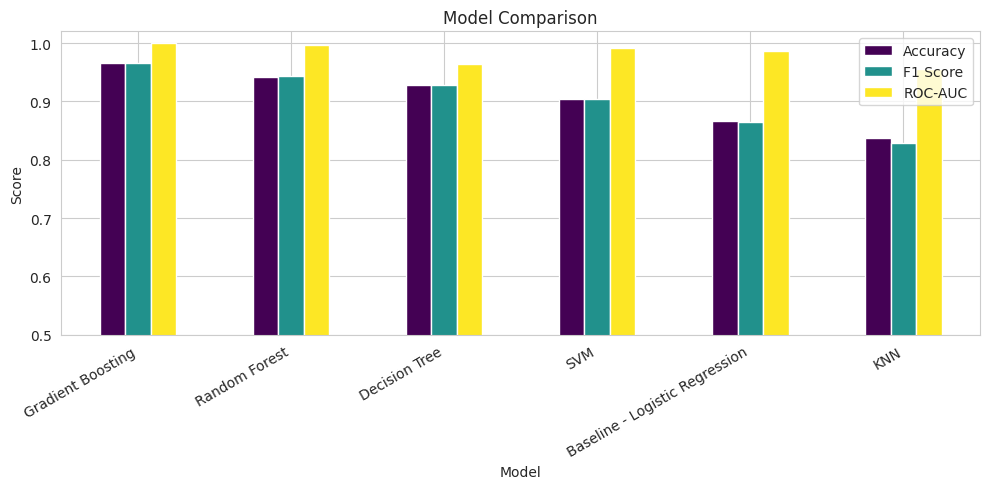

In [ ]:
comparison = results_df.sort_values(["F1 Score", "Accuracy"], ascending=False).reset_index(drop=True)
comparison["Rank"] = comparison.index + 1

display(comparison[["Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "Rank"]].round(4))

comparison.set_index("Model")[["Accuracy", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5), colormap="viridis")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0.5, 1.02)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Observations

- Ranking by F1-score: Gradient Boosting, Random Forest, Decision Tree, SVM, Logistic Regression (baseline), KNN.
- The ensemble models beat the baseline by about 8 to 10 percentage points in F1-score.
- In the chart, ROC-AUC bars are the tallest for every model, while accuracy and F1 bars are almost equal. This shows that precision and recall are balanced across classes.

# **7.3 Best Model Selection**

Best model: Gradient Boosting
                     precision    recall  f1-score   support

Insufficient_Weight       0.96      1.00      0.98        53
      Normal_Weight       0.95      0.95      0.95        57
 Overweight_Level_I       0.96      0.91      0.93        55
Overweight_Level_II       0.98      0.97      0.97        58
     Obesity_Type_I       0.93      1.00      0.97        70
    Obesity_Type_II       0.98      0.95      0.97        60
   Obesity_Type_III       1.00      0.98      0.99        65

           accuracy                           0.97       418
          macro avg       0.97      0.97      0.97       418
       weighted avg       0.97      0.97      0.97       418



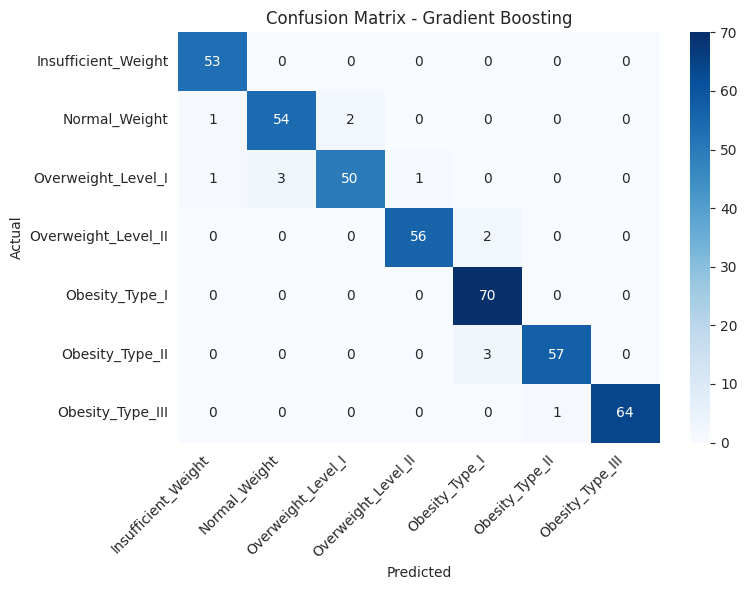

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

best_name = comparison.loc[0, "Model"]
best_model = trained_models[best_name]
print("Best model:", best_name)

y_pred_best = best_model.predict(X_test_final)
print(classification_report(y_test, y_pred_best, target_names=list(target_order.keys())))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt="d", cmap="Blues",
            xticklabels=target_order.keys(), yticklabels=target_order.keys())
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Observations

- Overall accuracy and weighted F1 are both 0.97 on 418 test records.
- Every class has an F1-score of 0.93 or higher. Obesity Type III (0.99) and Insufficient Weight (0.98) are predicted best.
- Overweight Level I has the lowest recall (0.91) and Normal Weight the lowest F1 (0.95), which makes them the hardest classes.
- 404 of 418 test records were classified correctly, with only 14 errors.
- Almost all errors are between neighbouring classes, for example Overweight Level I predicted as Normal Weight (3), and Obesity Type II predicted as Obesity Type I (3). No record was predicted more than one level away.
- Obesity Type I (70/70) and Insufficient Weight (53/53) were classified perfectly.

### 7.3 Best Model Selection

**Why this model was selected:**
- Gradient Boosting ranked first, with the highest accuracy (0.9665), precision (0.9671), recall (0.9665), F1-score (0.9664) and ROC-AUC (0.9995) on the test set.
- Its 5-fold cross-validation accuracy (0.9664) matches the test accuracy, which confirms the result is consistent and not due to a lucky split.
- It outperformed the baseline Logistic Regression (F1 0.8642) by about 10 percentage points.

**Strengths:**
- High and balanced performance across all seven classes, with every class F1-score at or above 0.93.
- It can capture non-linear relationships between lifestyle and body-measurement features, which linear models and KNN cannot.
- It is lightweight and fast to train, so it is easy to deploy.

**Limitations:**
- Nearly all errors (14 of 418) occur between neighbouring classes such as Overweight Level I vs Normal Weight, where the class boundaries are close.
- Training accuracy reaches 1.00, so the model fits the training data perfectly and needs regularization or tuning to stay robust on new data.
- It is less interpretable than simple models such as Logistic Regression or a single Decision Tree.
- Predictions depend heavily on Height and Weight, which closely determine the obesity category.


### 7.4 Overfitting / Underfitting Analysis

- **Training performance:** Gradient Boosting and Random Forest reached 1.00 training accuracy, and the Decision Tree reached 0.99. Logistic Regression (0.90) and KNN (0.89) had the lowest training accuracy.
- **Testing performance:** Gradient Boosting scored 0.9665 on the test set, Random Forest 0.9426, and Decision Tree 0.9282. The weakest were KNN (0.8373) and Logistic Regression (0.8660).
- **Generalization capability:**
  - Gradient Boosting has the smallest train-test gap among the high-performing models (about 0.03), and its cross-validation accuracy (0.9664) equals its test accuracy, so it generalizes best.
  - Random Forest and Decision Tree show slightly larger gaps (about 0.06), which indicates mild overfitting.
  - SVM has a similar gap of about 0.06, with a cross-validation accuracy (0.9053) close to its test accuracy.
  - Logistic Regression and KNN have lower scores on both training and test data, which suggests mild underfitting because they are too simple to capture the patterns fully.
- **Conclusion:** Gradient Boosting gives the best balance of high accuracy and consistent performance on unseen data.

# **8. Hyperparameter Tuning**

# **8.1 Define Parameter Grids and Run the Search**

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import time

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    "Baseline - Logistic Regression": {
        "logisticregression__C": [0.1, 1, 10, 100],
    },
    "KNN": {
        "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11],
        "kneighborsclassifier__weights": ["uniform", "distance"],
    },
    "Decision Tree": {
        "decisiontreeclassifier__max_depth": [5, 8, 10, 15],
        "decisiontreeclassifier__min_samples_split": [2, 5, 10],
        "decisiontreeclassifier__criterion": ["gini", "entropy"],
    },
    "Random Forest": {
        "randomforestclassifier__n_estimators": [100, 200],
        "randomforestclassifier__max_depth": [8, 12, None],
        "randomforestclassifier__min_samples_split": [2, 5],
    },
    "SVM": {
        "svc__C": [1, 10, 50],
        "svc__gamma": ["scale", 0.1],
    },
    "Gradient Boosting": {
        "histgradientboostingclassifier__learning_rate": [0.05, 0.1, 0.2],
        "histgradientboostingclassifier__max_depth": [3, 5, None],
        "histgradientboostingclassifier__max_iter": [100, 200],
    },
}

tuned_models = {}
tuning_summary = []

for name, grid in param_grids.items():
    start = time.time()
    search = GridSearchCV(
        estimator=trained_models[name],   # reuse the pipeline built earlier
        param_grid=grid,
        scoring="f1_weighted",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train_final, y_train)
    tuned_models[name] = search.best_estimator_

    tuning_summary.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": {k.split("__")[1]: v for k, v in search.best_params_.items()},
        "Time (s)": round(time.time() - start, 1),
    })
    print(f"{name} done in {time.time() - start:.1f}s")

tuning_df = pd.DataFrame(tuning_summary)
pd.set_option("display.max_colwidth", None)
display(tuning_df.round(4))

Baseline - Logistic Regression done in 4.8s
KNN done in 0.9s
Decision Tree done in 1.9s
Random Forest done in 32.0s
SVM done in 8.7s
Gradient Boosting done in 107.9s


,Model,Best CV F1,Best Parameters,Time (s)
0,Baseline - Logistic Regression,0.9520,{'C': 100},4.8
1,KNN,0.8300,"{'n_neighbors': 3, 'weights': 'distance'}",0.9
2,Decision Tree,0.9264,"{'criterion': 'entropy', 'max_depth': 15, 'min_samples_split': 2}",1.9
3,Random Forest,0.9453,"{'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}",32.0
4,SVM,0.9329,"{'C': 50, 'gamma': 'scale'}",8.7
5,Gradient Boosting,0.9707,"{'learning_rate': 0.2, 'max_depth': 3, 'max_iter': 100}",107.9


### Observations

- Gradient Boosting had the highest cross-validation F1 (0.9707), followed by Logistic Regression (0.9520) and Random Forest (0.9453). KNN was lowest (0.8300).
- Best settings: Gradient Boosting (learning_rate = 0.2, max_depth = 3), Random Forest (200 trees, unlimited depth), SVM (C = 50) and Logistic Regression (C = 100). A higher C means weaker regularization, which helped these models fit the data better.
- Tuning time grew with model complexity, from under 1 second for KNN to about 108 seconds for Gradient Boosting.

# 8.2 Evaluate Tuned Models on the Test Set

In [ ]:
tuned_results = []
for name, pipe in tuned_models.items():
    y_train_pred = pipe.predict(X_train_final)
    y_test_pred = pipe.predict(X_test_final)
    y_test_proba = pipe.predict_proba(X_test_final)

    tuned_results.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, average="weighted"),
        "Recall": recall_score(y_test, y_test_pred, average="weighted"),
        "F1 Score": f1_score(y_test, y_test_pred, average="weighted"),
        "ROC-AUC": roc_auc_score(y_test, y_test_proba, multi_class="ovr", average="weighted"),
    })

tuned_df = pd.DataFrame(tuned_results)
display(tuned_df.round(4))

,Model,Train Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline - Logistic Regression,0.9802,0.9641,0.9645,0.9641,0.9641,0.9969
1,KNN,1.0000,0.8445,0.8452,0.8445,0.8390,0.9476
2,Decision Tree,1.0000,0.9426,0.9423,0.9426,0.9421,0.9665
3,Random Forest,0.9988,0.9402,0.9439,0.9402,0.9404,0.9978
4,SVM,1.0000,0.9354,0.9362,0.9354,0.9352,0.9971
5,Gradient Boosting,1.0000,0.9689,0.9699,0.9689,0.9689,0.9989


### Observations

- Gradient Boosting scored highest on the test set (accuracy 0.9689, F1 0.9689, ROC-AUC 0.9989).
- Logistic Regression improved sharply to 0.9641 accuracy and came second, close to the ensemble models.
- KNN remained the weakest (accuracy 0.8445), so tuning could not make up for its sensitivity to feature scale and class overlap.
- ROC-AUC stayed above 0.94 for all models, so every model still separates the classes well.

# 8.3 Before vs After Tuning

,Model,Accuracy (Before),F1 Score (Before),Accuracy (After),F1 Score (After),F1 Improvement
0,Baseline - Logistic Regression,0.8660,0.8642,0.9641,0.9641,0.0999
1,KNN,0.8373,0.8280,0.8445,0.8390,0.0110
2,Decision Tree,0.9282,0.9282,0.9426,0.9421,0.0139
3,Random Forest,0.9426,0.9428,0.9402,0.9404,-0.0024
4,SVM,0.9043,0.9043,0.9354,0.9352,0.0309
5,Gradient Boosting,0.9665,0.9664,0.9689,0.9689,0.0025


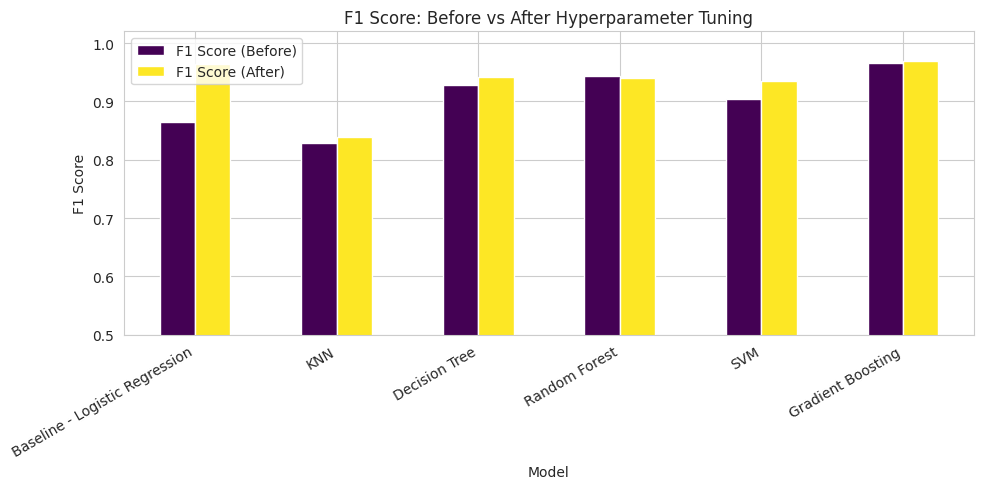

In [ ]:
compare = results_df[["Model", "Accuracy", "F1 Score"]].merge(
    tuned_df[["Model", "Accuracy", "F1 Score"]],
    on="Model", suffixes=(" (Before)", " (After)")
)
compare["F1 Improvement"] = compare["F1 Score (After)"] - compare["F1 Score (Before)"]
display(compare.round(4))

compare.set_index("Model")[["F1 Score (Before)", "F1 Score (After)"]].plot(
    kind="bar", figsize=(10, 5), colormap="viridis")
plt.title("F1 Score: Before vs After Hyperparameter Tuning")
plt.ylabel("F1 Score")
plt.ylim(0.5, 1.02)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Observations

- Logistic Regression gained the most (F1 from 0.8642 to 0.9641, about +10 points), followed by SVM (+3.1 points).
- Decision Tree and KNN improved modestly (+1.4 and +1.1 points), and Gradient Boosting gained a small +0.25 points because it was already near its best.
- Random Forest dropped slightly (-0.24 points), which is within normal variation, since tuning optimizes cross-validation and not the test set.

# **8.4 Final Best Model**

In [ ]:
final_ranking = tuned_df.sort_values(["F1 Score", "Accuracy"], ascending=False).reset_index(drop=True)
final_ranking["Rank"] = final_ranking.index + 1
display(final_ranking[["Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "Rank"]].round(4))

final_name = final_ranking.loc[0, "Model"]
final_model = tuned_models[final_name]
print("Final best model after tuning:", final_name)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Rank
0,Gradient Boosting,0.9689,0.9699,0.9689,0.9689,0.9989,1
1,Baseline - Logistic Regression,0.9641,0.9645,0.9641,0.9641,0.9969,2
2,Decision Tree,0.9426,0.9423,0.9426,0.9421,0.9665,3
3,Random Forest,0.9402,0.9439,0.9402,0.9404,0.9978,4
4,SVM,0.9354,0.9362,0.9354,0.9352,0.9971,5
5,KNN,0.8445,0.8452,0.8445,0.8390,0.9476,6


Final best model after tuning: Gradient Boosting


### Observations

- Gradient Boosting stays in first place after tuning (accuracy 0.9689, F1 0.9689, ROC-AUC 0.9989), so it is selected as the final model.
- The ranking changed in the middle: Logistic Regression moved up to second, and Random Forest fell to fourth.
- Final ranking: Gradient Boosting, Logistic Regression, Decision Tree, Random Forest, SVM, KNN.

## 9. Conclusion

### Final Findings

- The project aimed to predict an individual's obesity level (seven classes) from eating habits, lifestyle and physical-condition data, as a multi-class classification problem.
- The data was cleaned by removing duplicate rows and treating outliers. Skewness in Age was reduced with a log transformation, categorical features were encoded, and weakly informative features (SMOKE and the Automobile, Motorbike and Bike transport categories) were dropped.
- Six lightweight models were built using pipelines: Logistic Regression (baseline), KNN, Decision Tree, Random Forest, SVM and Gradient Boosting.
- Hyperparameter tuning with GridSearchCV (5-fold stratified cross-validation) improved five of the six models. The largest gain was for Logistic Regression, whose accuracy rose from 86.60% to 96.41%.
- **Gradient Boosting was the best model** both before and after tuning. After tuning it reached 96.89% accuracy, an F1-score of 0.9689 and a ROC-AUC of 0.9989, and its cross-validation F1 (0.9707) agreed closely with its test score.
- Final ranking after tuning: Gradient Boosting, Logistic Regression, Decision Tree, Random Forest, SVM and KNN. KNN performed worst (84.45% accuracy).
- Errors were rare and occurred only between neighbouring obesity levels, so no record was predicted more than one class away from its true class.

### Business Impact

- **Early screening:** Healthcare providers and wellness programs can use the model to estimate a person's obesity level quickly from a short lifestyle questionnaire and basic body measurements, then flag high-risk individuals for early intervention.
- **Personalized recommendations:** Insights into the factors linked to higher obesity levels, such as eating habits, physical activity and family history, can guide targeted diet and exercise advice.
- **Cost reduction:** Preventing obesity-related conditions such as diabetes, hypertension and heart disease reduces long-term healthcare costs for individuals, insurers and health systems.
- **Public health planning:** Organizations can use the findings to design awareness campaigns and prioritize interventions for groups with risky lifestyle patterns.
- **Easy deployment:** The models are lightweight and fast to train and run, so the solution can be wrapped in a simple web application or API for real-time predictions.
- **Limitations and future work:** Predictions depend strongly on Height and Weight, and the model should be validated on new real-world data before clinical use. Future work can include more features (sleep, stress, medical history) and deployment with Flask or FastAPI.